# 1800-04 — Loss of orthogonality in CG on PALMER1C

Companion notebook to Hager & Zhang (2013), *The Limited Memory Conjugate Gradient Method*, SIAM J. Optim. 23(4), pp. 2150–2168.

**Goal.**
1. Reproduce the columns of Table 1.1 [HZ13, p. 2151]: $\|g_k\|$ and $\rho_k=\operatorname{dist}\{g_k/\|g_k\|,\mathcal S_k\}$ for L-BFGS and CG.
2. Inspect the subspace $\mathcal S_k$ for CG at $k=3$ (orthogonality still holds) and $k=5$ (orthogonality lost).

Definitions of $\mathcal S_k$ and $\rho_k$: companion note `1800-02`. Here $\mathcal S_k=\operatorname{span}\{d_{k-1},\dots,d_{k-m_k}\}$, $m_k=\min\{k,6\}$.

Every floating-point run is compared with the **same CG run in exact rational arithmetic** (`fractions.Fraction`), where $g_k\perp\mathcal S_k$ must hold [HZ13, pp. 2159–2160].

In [1]:
import re
import urllib.request
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import subspace_angles

np.set_printoptions(formatter={"float_kind": lambda v: f"{v: .3e}"}, linewidth=120)

PALMER1C_SIF = "https://raw.githubusercontent.com/ralna/SIF/refs/heads/master/PALMER1C.SIF"
WINDOW = 6       # number of directions kept in S_k (Table 1.1)
K = 16           # iterations shown in Table 1.1 (k = 0..15)

## 1. PALMER1C

$f(a)=\|Va-y\|^2$, $V_{ik}=x_i^{2k}$, so $g(a)=2(Aa-b)$ with $A=V^\top V$, $b=V^\top y$. Start point: the SIF default $a_0=(1,\dots,1)$.

The data are read as **strings**, so we can build both a floating-point and an exact rational copy of $A$ and $b$.

In [2]:
def read_sif_strings(url):
    with urllib.request.urlopen(url) as response:
        text = response.read().decode("utf-8")
    x = {int(i): v.replace("D", "E") for i, v in re.findall(r"^\s*RE\s+X(\d+)\s+(\S+)", text, re.M)}
    y = {int(i): v.replace("D", "E") for i, v in re.findall(r"^\s*RE\s+Y(\d+)\s+(\S+)", text, re.M)}
    idx = sorted(x)
    return [x[i] for i in idx], [y[i] for i in idx]

xs, ys = read_sif_strings(PALMER1C_SIF)

# floating point
x, y = np.array(xs, float), np.array(ys, float)
V = np.vander(x**2, N=8, increasing=True)
A, b = V.T @ V, V.T @ y

# exact rationals
xq = [Fraction(s) for s in xs]; yq = [Fraction(s) for s in ys]
Vq = [[(xi * xi) ** k for k in range(8)] for xi in xq]
Aq = [[sum(Vq[i][r] * Vq[i][c] for i in range(len(xq))) for c in range(8)] for r in range(8)]
bq = [sum(Vq[i][r] * yq[i] for i in range(len(xq))) for r in range(8)]

print(f"M = {len(xs)} data points, cond(A) = {np.linalg.cond(A):.3e}")

M = 35 data points, cond(A) = 1.263e+12


## 2. Algorithms

Both use an exact line search on the quadratic, $\alpha_k=-g_k^\top d_k/(2\,d_k^\top A d_k)$ (proof: companion note `1800-03`, Corollary 1), and compute the gradient as a black box $g(a)=2(Aa-b)$ [HZ13, p. 2152].

- **CG**: PRP+ [HZ13, p. 2150], $\beta_k=\max\{0,\ g_{k+1}^\top(g_{k+1}-g_k)/\|g_k\|^2\}$.
- **L-BFGS**: unscaled ($H_0=I$), memory 8 [HZ13, p. 2150].

`run_cg` stores every $g_k$ and $d_k$ so that $\mathcal S_k$ can be inspected later.

In [3]:
def grad(a):
    return 2.0 * (A @ a - b)

def exact_step(g, d):
    return -(g @ d) / (2.0 * d @ (A @ d))

def run_cg(a0, iters=K):
    a, g = a0.copy(), grad(a0)
    d = -g
    G, D = [g], [d]
    for _ in range(iters):
        a = a + exact_step(g, d) * d
        g_new = grad(a)
        beta = max(0.0, g_new @ (g_new - g) / (g @ g))
        d = -g_new + beta * d
        g = g_new
        G.append(g); D.append(d)
    return G, D

def run_lbfgs(a0, iters=K, mem=8):
    a, g = a0.copy(), grad(a0)
    S, Y, G, D = [], [], [], []
    for _ in range(iters + 1):
        q, alph = g.copy(), []
        for s, yv in zip(reversed(S), reversed(Y)):
            al = (s @ q) / (yv @ s); alph.append(al); q -= al * yv
        for (s, yv), al in zip(zip(S, Y), reversed(alph)):
            q += s * (al - (yv @ q) / (yv @ s))
        d = -q
        G.append(g); D.append(d)
        a_new = a + exact_step(g, d) * d
        g_new = grad(a_new)
        S.append(a_new - a); Y.append(g_new - g)
        S, Y = S[-mem:], Y[-mem:]
        a, g = a_new, g_new
    return G, D

In [4]:
# exact rational CG (same PRP+ algorithm); stops when g = 0
def qdot(u, v): return sum(p * q for p, q in zip(u, v))
def qmatvec(M, v): return [qdot(row, v) for row in M]
def qgrad(a): return [2 * (r - s) for r, s in zip(qmatvec(Aq, a), bq)]

def run_cg_exact(iters=K):
    a = [Fraction(1)] * 8
    g = qgrad(a); d = [-t for t in g]
    G, D = [g], [d]
    for _ in range(iters):
        alpha = -qdot(g, d) / (2 * qdot(d, qmatvec(Aq, d)))
        a = [ai + alpha * di for ai, di in zip(a, d)]
        g_new = qgrad(a)
        G.append(g_new)
        if all(t == 0 for t in g_new):
            break
        beta = max(Fraction(0), qdot(g_new, [p - q for p, q in zip(g_new, g)]) / qdot(g, g))
        d = [-p + beta * q for p, q in zip(g_new, d)]
        g = g_new
        D.append(d)
    return G, D

a0 = np.ones(8)
G_cg, D_cg = run_cg(a0)
G_lb, D_lb = run_lbfgs(a0)
G_ex, D_ex = run_cg_exact()
print(f"exact CG reaches g = 0 at k = {len(G_ex) - 1}  (n = 8)")

exact CG reaches g = 0 at k = 8  (n = 8)


## 3. Table 1.1

$\rho_k$ is computed as a relative least-squares residual (companion note `1800-02`, Proposition 1(b)):
$\rho_k=\|g_k-ZZ^\top g_k\|/\|g_k\|$, with $Z$ an orthonormal basis of $\mathcal S_k$ from a QR factorization.

For the exact run we also report $\max_j |\cos\angle(g_k,d_j)|$ over $d_j\in\mathcal S_k$, computed **exactly**: it is $0$ iff $g_k\perp\mathcal S_k$.

In [5]:
def window(D, k):
    return [D[j] for j in range(max(0, k - WINDOW), k)][::-1]   # d_{k-1}, ..., d_{k-m_k}

def rho(g, dirs):
    if not dirs:
        return 1.0
    Z, _ = np.linalg.qr(np.column_stack(dirs))
    return np.linalg.norm(g - Z @ (Z.T @ g)) / np.linalg.norm(g)

def exact_max_inner(k):
    # exact: max_j |g_k^T d_j| over the window (0 means g_k ⟂ S_k exactly)
    return max((abs(qdot(G_ex[k], d)) for d in window(D_ex, k)), default=Fraction(0))

print(f"{'k':>3} {'||g|| L-BFGS':>13} {'||g|| CG':>13} {'rho L-BFGS':>13} {'rho CG':>13} {'exact CG: max|g^T d|':>22}")
rho_lb, rho_cg = [], []
for k in range(K):
    rho_lb.append(rho(G_lb[k], window(D_lb, k)))
    rho_cg.append(rho(G_cg[k], window(D_cg, k)))
    ex = str(exact_max_inner(k)) if k < len(G_ex) - 1 else "g = 0"
    print(f"{k:>3} {np.linalg.norm(G_lb[k]):13.6e} {np.linalg.norm(G_cg[k]):13.6e} "
          f"{rho_lb[k]:13.6e} {rho_cg[k]:13.6e} {ex:>22}")

  k  ||g|| L-BFGS      ||g|| CG    rho L-BFGS        rho CG   exact CG: max|g^T d|
  0  5.150804e+08  5.150804e+08  1.000000e+00  1.000000e+00                      0
  1  1.995189e+05  1.995189e+05  1.000000e+00  1.000000e+00                      0
  2  1.641922e+03  1.641922e+03  1.000000e+00  1.000000e+00                      0
  3  1.530095e+03  1.530095e+03  1.000000e+00  1.000000e+00                      0
  4  5.456873e+02  9.278367e+05  1.000000e+00  5.538346e-04                      0
  5  5.512577e+01  5.456874e+02  1.000000e+00  3.023522e-09                      0


  6  2.596300e+00  5.514606e+01  1.000000e+00  2.661850e-02                      0


  7  5.573903e-02  2.296492e+03  1.000000e+00  2.749949e-09                      0
  8  1.395263e-01  4.275686e+03  9.982973e-01  6.744552e-09                  g = 0
  9  1.110557e-07  1.002325e+02  9.678795e-01  2.590275e-02                  g = 0
 10  3.420716e-07  3.431798e+00  2.226027e-01  1.072384e-06                  g = 0
 11  5.244999e-08  1.058973e+01  7.971744e-01  1.532916e-03                  g = 0
 12  9.589490e-07  1.034402e+01  6.490146e-02  7.032799e-06                  g = 0
 13  2.587604e-06  4.723444e+00  2.282603e-01  8.740799e-09                  g = 0
 14  5.745726e-06  4.779674e+01  7.867421e-01  5.649974e-02                  g = 0
 15  5.182899e-06  4.852503e+02  9.968118e-01  5.875796e-09                  g = 0


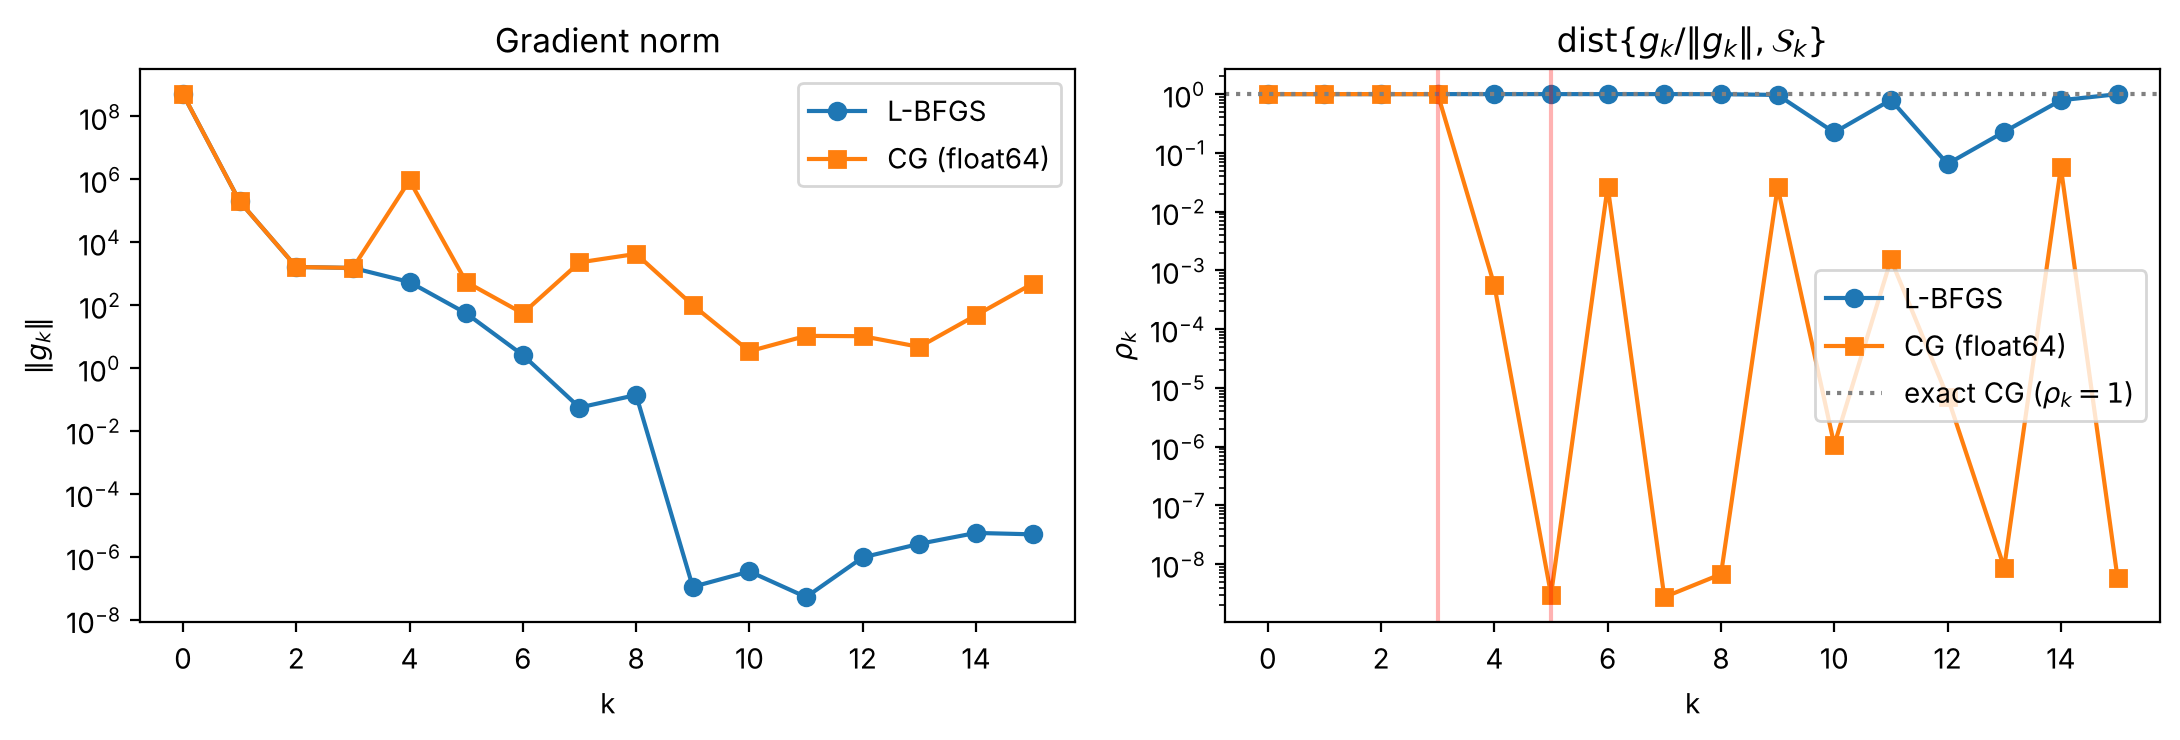

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ks = np.arange(K)
ax[0].semilogy(ks, [np.linalg.norm(g) for g in G_lb[:K]], "o-", label="L-BFGS")
ax[0].semilogy(ks, [np.linalg.norm(g) for g in G_cg[:K]], "s-", label="CG (float64)")
ax[0].set(xlabel="k", ylabel=r"$\|g_k\|$", title="Gradient norm"); ax[0].legend()
ax[1].semilogy(ks, rho_lb, "o-", label="L-BFGS")
ax[1].semilogy(ks, rho_cg, "s-", label="CG (float64)")
ax[1].axhline(1, color="gray", ls=":", label="exact CG ($\\rho_k=1$)")
for kk in (3, 5):
    ax[1].axvline(kk, color="red", alpha=0.3)
ax[1].set(xlabel="k", ylabel=r"$\rho_k$", title=r"$\mathrm{dist}\{g_k/\|g_k\|,\mathcal{S}_k\}$"); ax[1].legend()
plt.tight_layout(); plt.show()

**Comparison with the paper.** The qualitative behaviour matches Table 1.1: identical up to $k=3$, CG loses orthogonality at $k=4$, and $\rho_5\approx 3\times10^{-9}$ (paper: $2.97\times10^{-9}$). The numbers themselves differ: the paper reports $\|g_0\|=1.236601\times10^{4}$, while $a_0=(1,\dots,1)$ gives $\|g_0\|\approx5.15\times10^{8}$, so the paper used a start point or scaling that is not stated.

## 4. Inspecting $\mathcal S_k$ for CG

For $k=3$ and $k=5$ (both $<6$, so $\mathcal S_k=\operatorname{span}\{d_0,\dots,d_{k-1}\}$) we look at:

1. **Angles** $\cos\angle(g_k,d_j)$ for each $d_j\in\mathcal S_k$: exact CG gives $0$.
2. **Coordinates** of $u_k=g_k/\|g_k\|$ in an orthonormal basis $Z$ of $\mathcal S_k$: $\|Z^\top u_k\|^2=1-\rho_k^2$.
3. **Conjugacy** of the stored directions, $C_{ij}=d_i^\top A d_j/\sqrt{(d_i^\top A d_i)(d_j^\top A d_j)}$: exact CG gives $C=I$. Loss of conjugacy is what lets $g_k$ fall back into $\mathcal S_k$.
4. **Is it the same subspace?** Principal angles between the float64 $\mathcal S_k$ and the exact $\mathcal S_k$.

In [7]:
def to_float(v):
    return np.array([float(t) for t in v])

def inspect(k):
    u = G_cg[k] / np.linalg.norm(G_cg[k])
    dirs = [D_cg[j] for j in range(k)]                    # d_0, ..., d_{k-1}
    dirs_ex = [to_float(D_ex[j]) for j in range(k)]
    Dn = np.column_stack([d / np.linalg.norm(d) for d in dirs])
    Z, _ = np.linalg.qr(Dn)

    print(f"=== k = {k}:  S_{k} = span{{d_0,...,d_{k-1}}},  rho_{k} = {rho(G_cg[k], dirs):.3e} ===\n")

    print("1) cos angle(g_k, d_j)")
    print("   float64:", Dn.T @ u)
    exact_cos = [float(qdot(G_ex[k], D_ex[j])) for j in range(k)]
    print("   exact  :", np.array(exact_cos), " (exact zeros)\n")

    c = Z.T @ u
    print("2) coordinates of u_k in S_k:  Z^T u_k =", c)
    print(f"   ||Z^T u_k||^2 = {c @ c:.12f},  1 - rho^2 = {1 - rho(G_cg[k], dirs)**2:.12f}\n")

    AD = np.column_stack([A @ d for d in dirs])
    M = np.column_stack(dirs).T @ AD
    s = np.sqrt(np.diag(M))
    print("3) conjugacy  C_ij = d_i^T A d_j / sqrt(d_i^T A d_i d_j^T A d_j)   (exact CG: identity)")
    print(M / np.outer(s, s), "\n")

    ang = subspace_angles(np.column_stack(dirs), np.column_stack(dirs_ex))
    print("4) principal angles (rad) between float64 S_k and exact S_k:", np.sort(ang))
    return c

In [8]:
c3 = inspect(3)

=== k = 3:  S_3 = span{d_0,...,d_2},  rho_3 = 1.000e+00 ===

1) cos angle(g_k, d_j)
   float64: [ 9.616e-05 -4.006e-12  1.067e-12]
   exact  : [ 0.000e+00  0.000e+00  0.000e+00]  (exact zeros)

2) coordinates of u_k in S_k:  Z^T u_k = [ 9.616e-05 -3.725e-08  1.090e-12]
   ||Z^T u_k||^2 = 0.000000009247,  1 - rho^2 = 0.000000009247

3) conjugacy  C_ij = d_i^T A d_j / sqrt(d_i^T A d_i d_j^T A d_j)   (exact CG: identity)
[[ 1.000e+00 -5.116e-15  9.446e-08]
 [-3.784e-15  1.000e+00  5.482e-14]
 [ 9.446e-08 -2.787e-13  1.000e+00]] 

4) principal angles (rad) between float64 S_k and exact S_k: [ 1.963e-16  6.054e-15  4.433e-13]


In [9]:
c5 = inspect(5)

=== k = 5:  S_5 = span{d_0,...,d_4},  rho_5 = 2.886e-09 ===

1) cos angle(g_k, d_j)
   float64: [ 5.538e-04 -9.016e-08  1.435e-11 -1.160e-12  3.183e-13]
   exact  : [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00]  (exact zeros)

2) coordinates of u_k in S_k:  Z^T u_k = [ 5.538e-04 -3.047e-07  7.562e-10 -5.324e-08  1.000e+00]
   ||Z^T u_k||^2 = 1.000000000000,  1 - rho^2 = 1.000000000000

3) conjugacy  C_ij = d_i^T A d_j / sqrt(d_i^T A d_i d_j^T A d_j)   (exact CG: identity)
[[ 1.000e+00 -5.116e-15  9.446e-08 -2.415e-01  9.704e-01]
 [-3.784e-15  1.000e+00  5.482e-14  1.911e-06 -7.683e-06]
 [ 9.446e-08 -2.787e-13  1.000e+00  2.045e-12  1.909e-12]
 [-2.415e-01  1.911e-06  2.004e-12  1.000e+00 -2.836e-13]
 [ 9.704e-01 -7.683e-06  1.948e-12 -2.566e-13  1.000e+00]] 

4) principal angles (rad) between float64 S_k and exact S_k: [ 2.933e-16  7.322e-16  4.940e-14  1.831e-12  4.805e-10]


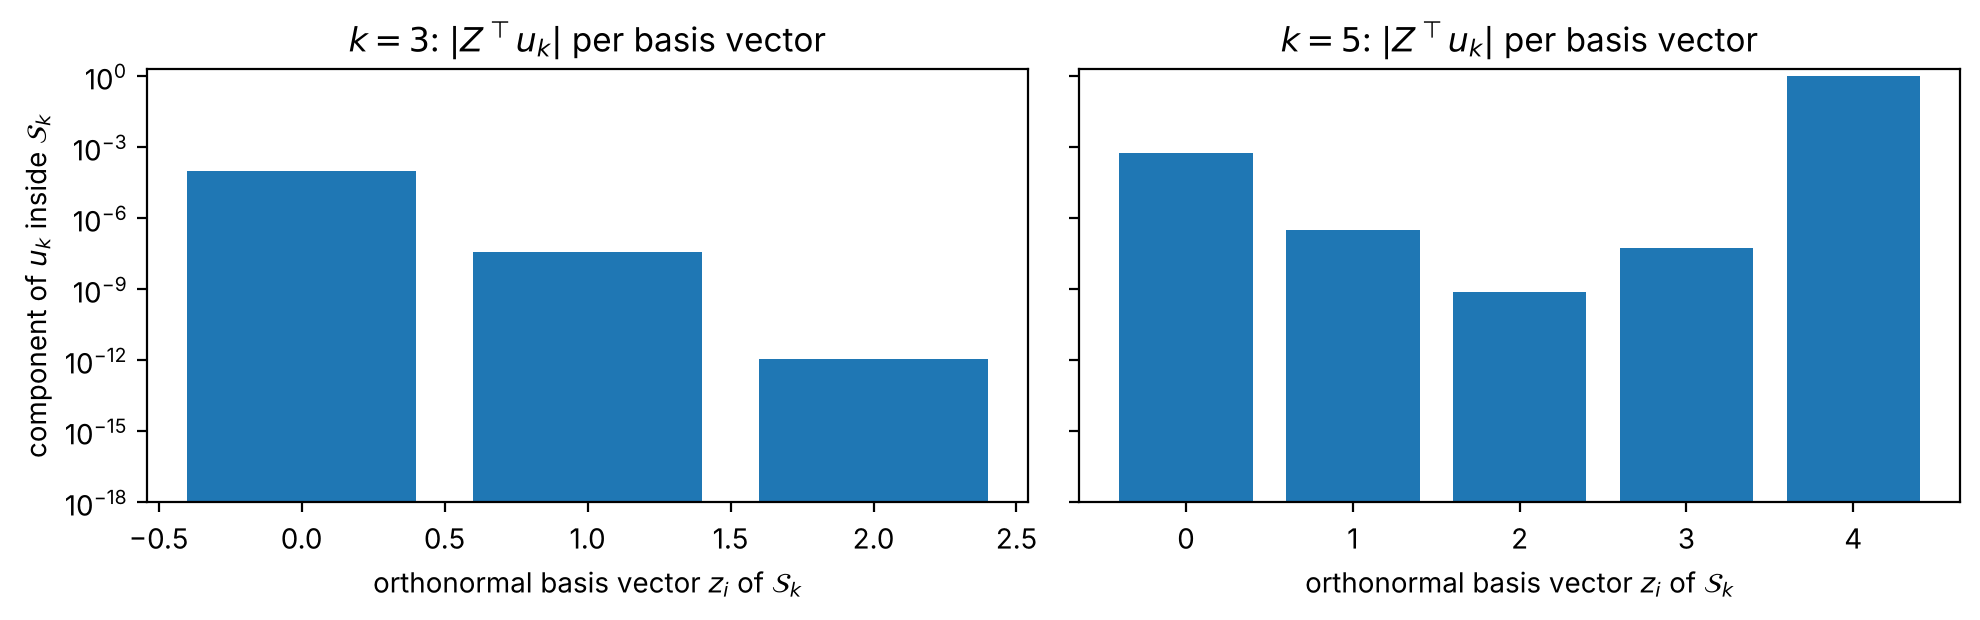

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a_, c, k in ((ax[0], c3, 3), (ax[1], c5, 5)):
    a_.bar(range(len(c)), np.abs(c))
    a_.set_yscale("log"); a_.set_ylim(1e-18, 2)
    a_.set(title=fr"$k={k}$: $|Z^\top u_k|$ per basis vector", xlabel=r"orthonormal basis vector $z_i$ of $\mathcal{S}_k$")
ax[0].set_ylabel("component of $u_k$ inside $\\mathcal{S}_k$")
plt.tight_layout(); plt.show()

## 5. Where did $g_k$ go? Float64 vs exact iterates

Rows: float64 iterate $k$. Columns: exact iterate $j$. Entry: $|\cos\angle|$. A $1$ off the diagonal means the float64 vector points in the direction of a *different* exact iterate. We also give the singular values of the normalized basis $[d_0/\|d_0\|,\dots,d_{k-1}/\|d_{k-1}\|]$: a tiny one means the stored directions are nearly linearly dependent.

In [11]:
GE = [to_float(g) for g in G_ex]
DE = [to_float(d) for d in D_ex]
def abscos(u, v): return abs(u @ v) / (np.linalg.norm(u) * np.linalg.norm(v))

print("|cos(g_k float64, g_j exact)|        j = 0 ... 7")
for k in range(8):
    print(f"k={k}", np.array([abscos(G_cg[k], GE[j]) for j in range(8)]))
print("\n|cos(d_k float64, d_j exact)|        j = 0 ... 7")
for k in range(7):
    print(f"k={k}", np.array([abscos(D_cg[k], DE[j]) for j in range(8)]))
for k in (3, 5):
    Dn = np.column_stack([D_cg[j] / np.linalg.norm(D_cg[j]) for j in range(k)])
    print(f"\nsingular values of normalized basis of S_{k}:", np.linalg.svd(Dn, compute_uv=False))

|cos(g_k float64, g_j exact)|        j = 0 ... 7
k=0 [ 1.000e+00  6.686e-18  5.521e-18  3.474e-18  4.830e-18  3.655e-18  9.386e-19  1.906e-18]
k=1 [ 5.915e-13  1.000e+00  1.374e-14  1.007e-14  9.820e-15  7.280e-15  4.380e-15  1.668e-15]
k=2 [ 9.957e-11  3.801e-12  1.000e+00  3.482e-13  2.481e-13  1.143e-13  1.140e-14  1.057e-14]
k=3 [ 9.616e-05  3.725e-08  7.421e-13  1.000e+00  2.396e-12  1.838e-12  1.229e-12  6.576e-13]
k=4 [ 1.000e+00  3.875e-04  1.231e-09  9.616e-05  5.538e-04  9.787e-16  1.796e-16  4.276e-16]
k=5 [ 5.538e-04  3.047e-07  7.560e-10  5.324e-08  1.000e+00  2.969e-09  4.643e-12  2.712e-12]
k=6 [ 2.400e-02  1.264e-02  1.042e-04  3.754e-05  1.329e-05  9.996e-01  2.522e-11  1.287e-11]
k=7 [ 9.997e-01  3.038e-04  6.869e-07  8.953e-07  3.190e-07  2.400e-02  2.750e-09  5.316e-13]

|cos(d_k float64, d_j exact)|        j = 0 ... 7
k=0 [ 1.000e+00  3.874e-04  3.188e-06  2.173e-06  9.523e-07  1.064e-07  5.035e-09  1.082e-10]
k=1 [ 3.874e-04  1.000e+00  8.229e-03  5.610e-03  2.458

## 6. Observations

**$k=3$: orthogonality is already slightly broken, but $\rho_3$ cannot show it.**
- $\rho_3$ prints as $1.000000$, yet $\cos\angle(g_3,d_0)\approx 9.6\times10^{-5}\neq0$ and $C_{02}\approx 9\times10^{-8}\neq0$.
- The reason: $1-\rho_3^2=\|Z^\top u_3\|^2\approx 9\times10^{-9}$, so $\rho_3\approx 1-5\times10^{-9}$. Near $1$, $\rho_k$ only sees the *square* of the error.
- $\mathcal S_3$ itself is computed accurately: principal angles to the exact $\mathcal S_3$ are $\le 5\times10^{-13}$.

**$k=4$: the gradient jumps back to the first direction.**
- The float64 $g_4$ is parallel to the exact $g_0=-d_0$ ($|\cos|=1.000000$), and $\|g_4\|\approx 9.3\times10^{5}\gg\|g_3\|$.
- So $g_4$ lies almost in $\mathcal S_4$ ($\rho_4\approx 5.5\times10^{-4}$). This is what the paper calls *returning to a previously explored subspace* [HZ13, p. 2156].

**$k=5$: CG repeats the exact iteration one step late.**
- $d_4$ (float64) is parallel to the exact $d_3$ ($|\cos|=0.999999$), so $d_0,\dots,d_4$ are nearly dependent: the smallest singular value of the normalized basis is $\approx 5\times10^{-7}$.
- The float64 $\mathcal S_5$ still coincides with the exact $\mathcal S_5$ (principal angles $\le 5\times10^{-10}$).
- The float64 $g_5$ is parallel to the exact $g_4$, which lies in the exact $\mathcal S_5$ (because $g_4=-d_4+\beta_3d_3$). Hence $\rho_5\approx 3\times10^{-9}$, and $u_5$ has all its weight on the last basis vector $z_5$.
- From here on, the float64 iterates track the exact ones with a delay of one step: $g_5\parallel g_4^{\rm ex}$, $g_6\approx g_5^{\rm ex}$, $d_5\parallel d_4^{\rm ex}$. The norms agree as well: $\|g_5^{\rm CG}\|=545.6874$ vs $\|g_4^{\rm L\text{-}BFGS}\|=545.6873$.
- At $k=7$ the gradient again points back along $g_0$, which starts a second delay.

**Summary.** The subspace $\mathcal S_k$ is not what goes wrong: it matches the exact one. What goes wrong is the gradient. Rounding errors put a small component of $g_k$ along old directions; for PALMER1C ($\operatorname{cond}(A)\approx1.3\times10^{12}$) this component becomes dominant within one step. CG then re-explores directions it has already searched, which costs extra iterations. L-BFGS keeps $\rho_k\approx1$ while it converges.